# 06 — Validation: What Do Archetypes Add to the Five Positions?

**Project:** Positionless NBA Player Archetypes · **Season:** 2025-26 · **Population:** 379 players with ≥ 500 minutes

The previous notebooks built a data-driven description of playing style: three PCA axes, **3 families** and **8
archetypes** from k-means, and a list of statistical unicorns and border players. None of these steps ever looked at a
player's position. This final notebook brings the positions back and asks three questions:

1. **Agreement.** How closely do the data-driven groups match the official positions? Are they a relabelling of
   positions, unrelated to them, or something in between?
2. **Added value.** For each style feature, how much of the variation between players does the position explain, and
   how much do the archetypes explain? Where exactly does the five-position system fall short?
3. **Meaning.** What does each archetype look like in real units, and do archetypes describe *how* players play or *how
   well* they play?

| Tool | Question it answers |
|---|---|
| **Adjusted Rand Index (ARI)** + permutation baseline | How similar are two partitions of the same players, compared with chance? |
| **Cross-tabulations** (counts, row and column %) | Which positions feed which archetypes, and how pure is each archetype? |
| **η² (eta-squared)** | What share of a feature's variance is explained by a grouping (the R² of a regression on group dummies)? |
| **Group medians and boxplots** | What does each archetype look like in real units, including stats never used for clustering? |

**Two versions of "position".** `pos` is the **listed** position (the roster label). `pos_played` is the position at
which the player logged the most minutes, estimated from play-by-play data. Using both prevents the conclusions from
depending on one imperfect label.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
pd.set_option('display.max_colwidth', 100)
sns.set_theme(style='whitegrid', context='notebook')

DATA = Path('../data') if Path('../data').exists() else Path('data')
POS_ORDER = ['PG', 'SG', 'SF', 'PF', 'C']
FAM_ORDER = ['On-Ball Creator', 'Off-Ball Perimeter', 'Big']
ORDER = ['Primary Creator', 'Shot-Making Guard', 'Secondary Scoring Wing', 'Spot-Up Floor Spacer',
         'Defensive Disruptor', 'Stretch Forward', 'Hub Big', 'Rim-Running Big']
SHOW = {'x3p_ar': '3PA rate', 'corner3_rate': 'corner-3 rate', 'mid_share': 'mid-range share',
        'rim_share': 'rim share', 'f_tr': 'FT rate', 'usg_percent': 'USG%', 'ast_percent': 'AST%',
        'tov_percent': 'TOV%', 'percent_assisted_x2p_fg': '% 2s assisted', 'orb_percent': 'ORB%',
        'drb_percent': 'DRB%', 'blk_percent': 'BLK%', 'stl_percent': 'STL%'}   # readable feature names
N_PERM = 1000            # label shuffles for the permutation baselines
SEED = 0

---
## 1. Load and Align the Tables

**Goal.** Load the clustering results (families, archetypes, silhouette), the anomaly classification, the 13 style
features in real units, and the full season table, which also contains efficiency and impact stats that were never
used to build the archetypes (TS%, BPM, WS/48, VORP, minutes).

**Why it matters.** Every comparison below pairs a label from one table with a value from another. A single
misaligned row would silently attach one player's archetype to another player's stats.

**What to look for.** All four tables have the same 379 players in the same order (checked with `assert`), and the
group sizes of each labelling.

In [2]:
arch = pd.read_csv(DATA / 'processed' / 'archetypes.csv')
anom = pd.read_csv(DATA / 'processed' / 'anomalies.csv')
raw = pd.read_csv(DATA / 'processed' / 'features_raw.csv')
full = pd.read_csv(DATA / 'processed' / 'nba_2025_26_mp500.csv')

for t in (anom, raw, full):
    assert (t['player_id'].values == arch['player_id'].values).all()
assert (full['pos'].values == arch['pos'].values).all()

FEAT = ['x3p_ar', 'corner3_rate', 'mid_share', 'rim_share', 'f_tr', 'usg_percent', 'ast_percent', 'tov_percent',
        'percent_assisted_x2p_fg', 'orb_percent', 'drb_percent', 'blk_percent', 'stl_percent']
assert all(f in raw.columns for f in FEAT)

LABELS = {'listed position': arch['pos'], 'played position': arch['pos_played'],
          '3 families': arch['family'], '8 archetypes': arch['archetype']}
names = arch['player']
print('players:', len(arch), '| style features:', len(FEAT))
print('missing labels:', {k: int(v.isna().sum()) for k, v in LABELS.items()})
print()
for k, v in LABELS.items():
    print(f'{k:>16}:', ', '.join(f'{g} {n}' for g, n in v.value_counts().items()))

players: 379 | style features: 13
missing labels: {'listed position': 0, 'played position': 0, '3 families': 0, '8 archetypes': 0}

 listed position: SG 101, PF 74, C 68, PG 68, SF 68
 played position: SG 85, C 76, PF 75, SF 73, PG 70
      3 families: Off-Ball Perimeter 175, On-Ball Creator 132, Big 72
    8 archetypes: Primary Creator 61, Secondary Scoring Wing 57, Stretch Forward 56, Defensive Disruptor 50, Spot-Up Floor Spacer 48, Shot-Making Guard 45, Rim-Running Big 31, Hub Big 31


### Findings: Data
- The four tables are row-aligned on `player_id`, and no player is missing a listed position, a played position, a
  family or an archetype.
- Group sizes are reasonably balanced: positions have 68–101 players (SG is the largest), families 72–175, and
  archetypes 31–61. No grouping is dominated by a single giant group, which keeps the ARI and η² comparisons fair.

---
## 2. Agreement with Positions: Adjusted Rand Index

**Goal.** Measure how similar the data-driven groupings are to the positions with the **Adjusted Rand Index**. ARI
looks at every *pair* of players and asks whether the two partitions agree on putting them together or apart; it is
then adjusted so that **0 = agreement expected by chance** and **1 = identical partitions** (group names do not
matter, only who is grouped with whom).

**Why it matters.** If archetypes were just positions under new names, the whole pipeline would add nothing. If they
were unrelated to positions, they would probably be capturing noise rather than basketball roles. The interesting
answer is in between, and ARI places us on that scale.

**A reference point.** The two position labels themselves are compared too: listed vs. played position shows how much
two *versions of the same concept* agree.

**What to look for.** ARI of families and archetypes against both position labels, compared with the
position-vs.-position reference.

In [3]:
pairs = [('8 archetypes', 'listed position'), ('8 archetypes', 'played position'),
         ('3 families', 'listed position'), ('3 families', 'played position'),
         ('listed position', 'played position'), ('3 families', '8 archetypes')]
ari = pd.DataFrame([(a, b, adjusted_rand_score(LABELS[a], LABELS[b])) for a, b in pairs],
                   columns=['grouping', 'compared with', 'ARI'])
ari.round(3)

,grouping,compared with,ARI
0,8 archetypes,listed position,0.143
1,8 archetypes,played position,0.158
2,3 families,listed position,0.170
3,3 families,played position,0.177
4,listed position,played position,0.538
5,3 families,8 archetypes,0.264


**Goal.** Check that the ARI values are **meaningfully above chance** with a permutation baseline: shuffle the
archetype (or family) labels across players 1,000 times, keeping the group sizes fixed, and recompute the ARI each
time. The shuffles show the range of ARI values that pure chance produces for groups of these sizes.

**Why it matters.** A low ARI could mean "related but different" or "no relation at all". The permutation
distribution separates the two: if the observed ARI is far outside it, the relationship is real even though the
agreement is modest.

**What to look for.** Where the observed value sits relative to the null distribution, the largest ARI any shuffle
reached, and how many standard deviations the observed value lies above the null mean.

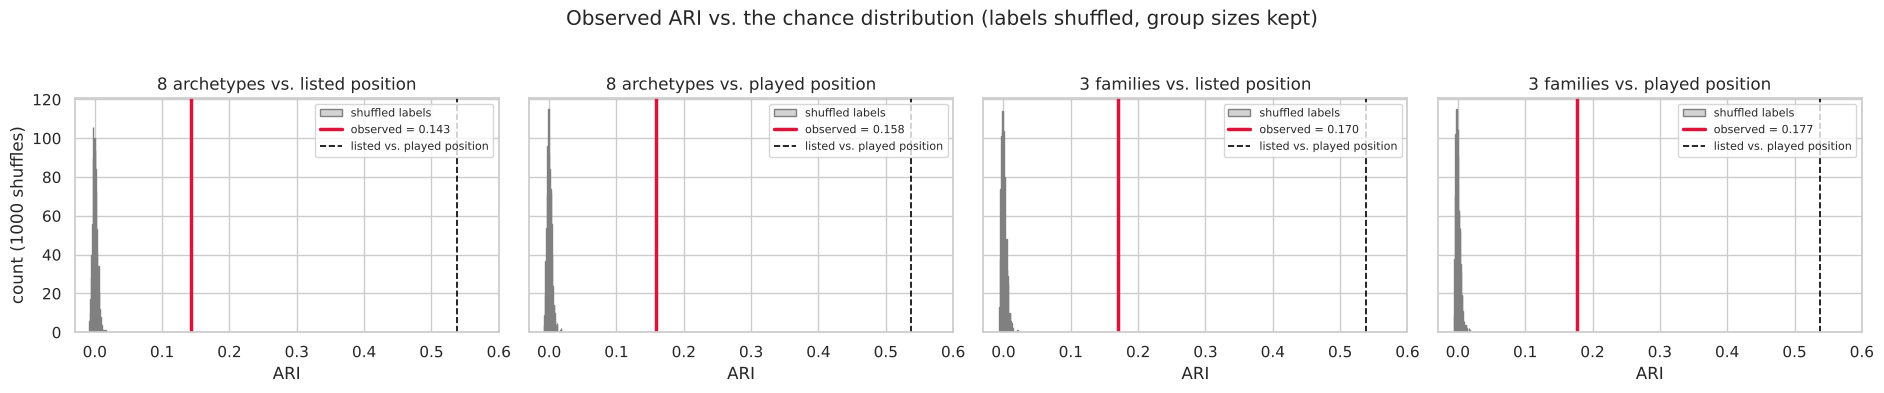

,grouping,compared with,observed ARI,null mean,null sd,null max,z vs. null,p (one-sided)
0,8 archetypes,listed position,0.143,-0.0001,0.0035,0.0162,41.5,0.001
1,8 archetypes,played position,0.158,0.0000,0.0036,0.0181,43.9,0.001
2,3 families,listed position,0.170,0.0002,0.0038,0.0215,44.4,0.001
3,3 families,played position,0.177,0.0000,0.0034,0.0176,52.0,0.001


In [4]:
rng = np.random.default_rng(SEED)
perm_rows, null = [], {}
for a, b in pairs[:4]:
    x, y = LABELS[a].values, LABELS[b].values
    obs = adjusted_rand_score(x, y)
    null[(a, b)] = np.array([adjusted_rand_score(rng.permutation(x), y) for _ in range(N_PERM)])
    n = null[(a, b)]
    perm_rows.append({'grouping': a, 'compared with': b, 'observed ARI': obs, 'null mean': n.mean(),
                      'null sd': n.std(), 'null max': n.max(), 'z vs. null': (obs - n.mean()) / n.std(),
                      'p (one-sided)': ((n >= obs).sum() + 1) / (N_PERM + 1)})
perm = pd.DataFrame(perm_rows)

fig, axes = plt.subplots(1, 4, figsize=(19, 3.8), sharey=True)
for ax, (a, b), r in zip(axes, pairs[:4], perm_rows):
    ax.hist(null[(a, b)], bins=30, color='lightgrey', edgecolor='grey', label='shuffled labels')
    ax.axvline(r['observed ARI'], color='crimson', lw=2.5, label=f"observed = {r['observed ARI']:.3f}")
    ax.axvline(adjusted_rand_score(LABELS['listed position'], LABELS['played position']), color='black', ls='--',
               lw=1.2, label='listed vs. played position')
    ax.set(title=f'{a} vs. {b}', xlabel='ARI', xlim=(-0.03, 0.6))
    ax.legend(fontsize=8, loc='upper right')
axes[0].set_ylabel(f'count ({N_PERM} shuffles)')
plt.suptitle('Observed ARI vs. the chance distribution (labels shuffled, group sizes kept)', y=1.03)
plt.tight_layout(); plt.show()
perm.round({'observed ARI': 3, 'null mean': 4, 'null sd': 4, 'null max': 4, 'z vs. null': 1, 'p (one-sided)': 4})

### Findings: Agreement with positions
- **Agreement is low but far above chance.** Archetypes vs. listed position give ARI = 0.14 and families vs. listed
  position 0.17; against the played position the values are slightly higher (0.16 and 0.18).
- **None of the 1,000 shuffles comes close.** Shuffled labels give ARI ≈ 0.000 ± 0.004, and the largest shuffled
  value is about 0.02. The observed values are **41–52 standard deviations** above the null mean, and no shuffle
  reached them, so p ≈ 0.001, the smallest p-value 1,000 shuffles can show.
- **For scale:** the two position labels agree with each other at ARI ≈ 0.54. Archetypes are much further from
  positions than one version of "position" is from another.
- ARI is also modest between the families and the archetypes (0.26), even though the archetypes nest roughly inside
  the families. ARI rewards partitions of the *same granularity*, so a 3-group and an 8-group labelling can never
  score highly against each other. This is one more reason to read the ARI values together with the
  cross-tabulations below rather than on their own.
- Played position matches the archetypes a little better than the roster label does, which makes sense: it reflects
  what players actually do on the floor, as the archetypes do.
- **Conclusion:** archetypes are **related to** positions (far from random) but are **not a relabelling** of them.
  The rest of this notebook looks at where they agree and where they differ.

---
## 3. Cross-Tabulations: Which Positions Become Which Roles?

**Goal.** Cross-tabulate the 8 archetypes against the listed position, as counts and as row percentages (the share of
each archetype coming from each position).

**Why it matters.** ARI is a single number; the cross-tabulation shows the structure behind it. Reading it like a
confusion matrix, a concentrated row is an archetype that corresponds to one position, a spread-out row is a role that
several positions perform, and a spread-out column is a position that hides several different jobs.

**What to look for.** Rows dominated by one cell (archetypes that *are* a position) versus rows spread over three or
four positions. **Purity** = the share of an archetype's players that come from its most common position.

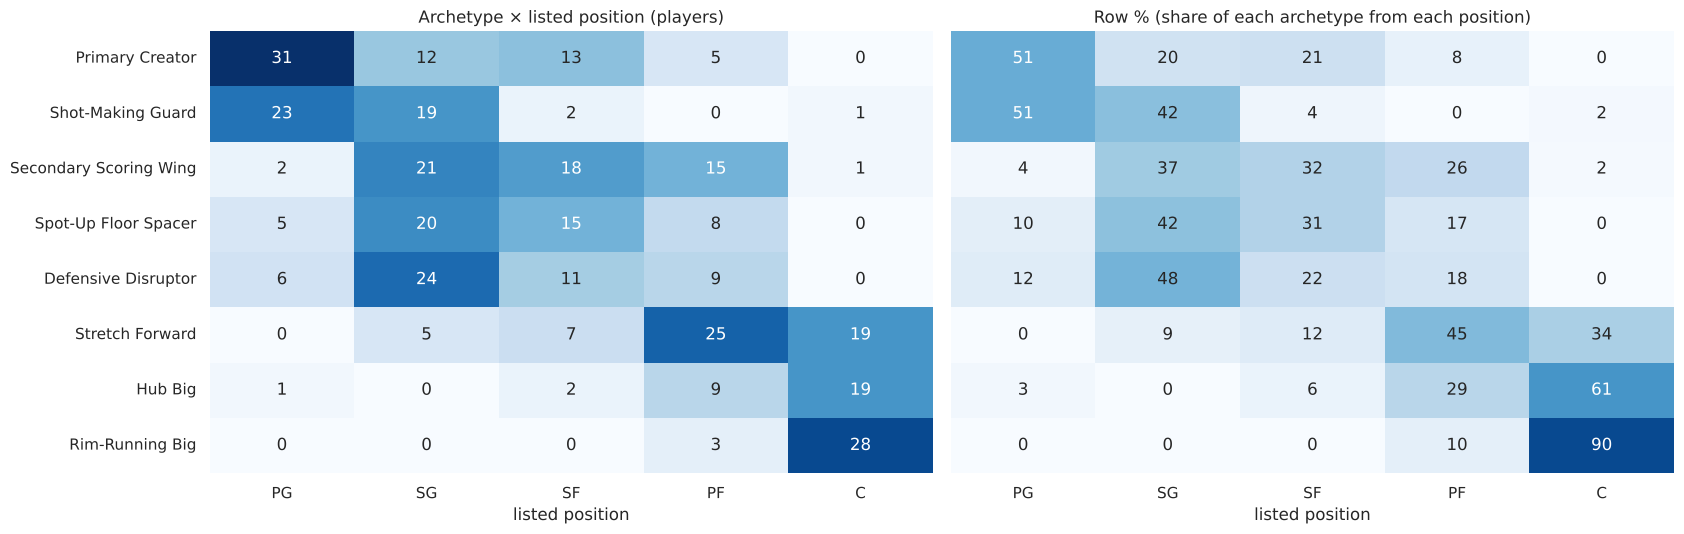

weighted mean purity: listed 50% | played 50%


,players,most common position,purity %,positions with ≥ 3 players,most common position (played),purity % (played)
archetype,,,,,,
Primary Creator,61,PG,51.0,4,PG,48.0
Shot-Making Guard,45,PG,51.0,2,PG,62.0
Secondary Scoring Wing,57,SG,37.0,3,SF,40.0
Spot-Up Floor Spacer,48,SG,42.0,4,SG,35.0
Defensive Disruptor,50,SG,48.0,4,SG,36.0
Stretch Forward,56,PF,45.0,4,C,43.0
Hub Big,31,C,61.0,2,C,71.0
Rim-Running Big,31,C,90.0,2,C,97.0


In [5]:
ct = pd.crosstab(arch['archetype'], arch['pos']).loc[ORDER, POS_ORDER]
row_pct = ct.div(ct.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
ax[0].set(title='Archetype × listed position (players)', xlabel='listed position', ylabel='')
sns.heatmap(row_pct, annot=True, fmt='.0f', cmap='Blues', cbar=False, vmin=0, vmax=100, ax=ax[1])
ax[1].set(title='Row % (share of each archetype from each position)', xlabel='listed position', ylabel='')
ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

def purity(table):
    return pd.DataFrame({'players': table.sum(axis=1),
                         'most common position': table.idxmax(axis=1),
                         'purity %': (table.max(axis=1) / table.sum(axis=1) * 100).round(0),
                         'positions with ≥ 3 players': (table >= 3).sum(axis=1)})

ct_played = pd.crosstab(arch['archetype'], arch['pos_played']).loc[ORDER, POS_ORDER]
pur = purity(ct).join(purity(ct_played)[['most common position', 'purity %']], rsuffix=' (played)')
print(f'weighted mean purity: listed {(pur["purity %"] * pur["players"]).sum() / pur["players"].sum():.0f}% | '
      f'played {(pur["purity % (played)"] * pur["players"]).sum() / pur["players"].sum():.0f}%')
pur

**Goal.** Read the same table the other way: for each **position**, how its players are distributed across the
archetypes (column percentages). Repeat for the played position.

**Why it matters.** This answers the coaching question directly: when a team says it needs "a power forward", which
jobs could that mean?

**What to look for.** Positions whose players spread over three or more archetypes, and whether the picture changes
when the play-by-play position is used instead of the roster label.

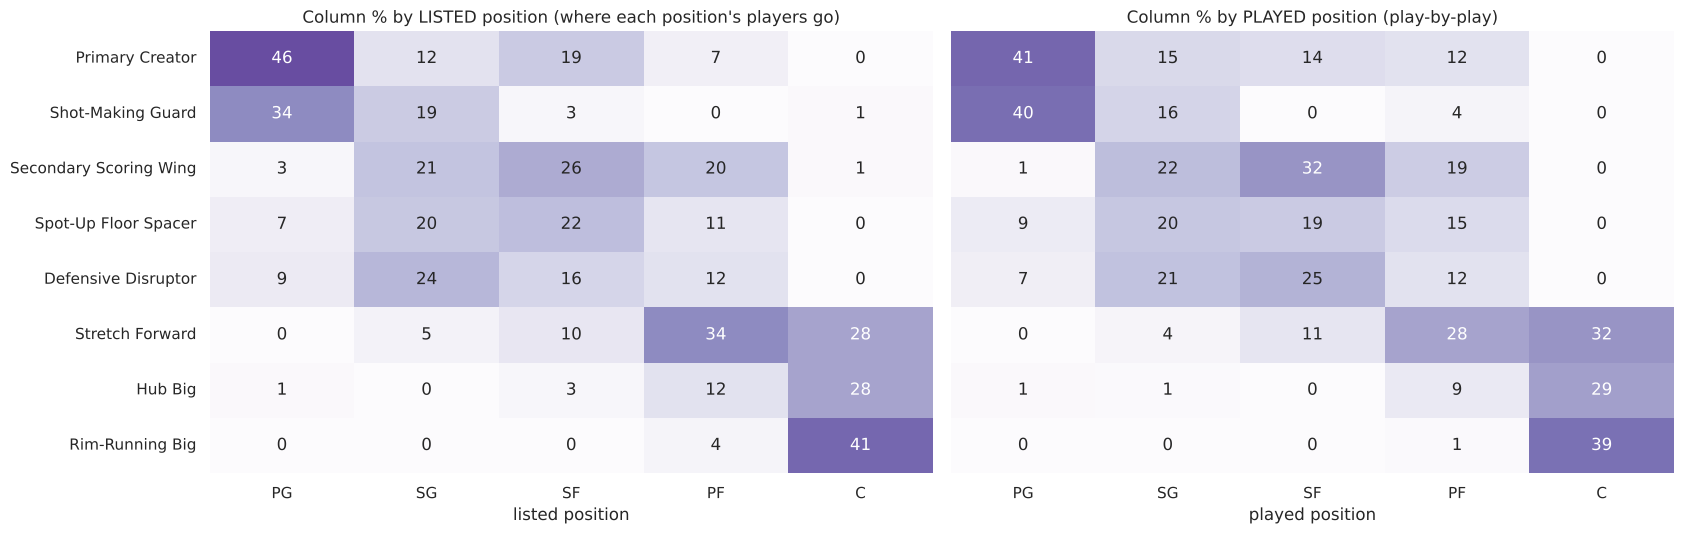

,archetypes with ≥ 10% of the position,largest archetype,its share %
pos,,,
PG,2,Primary Creator,46.0
SG,5,Defensive Disruptor,24.0
SF,5,Secondary Scoring Wing,26.0
PF,5,Stretch Forward,34.0
C,3,Rim-Running Big,41.0


In [6]:
col_pct = pd.crosstab(arch['archetype'], arch['pos'], normalize='columns').loc[ORDER, POS_ORDER] * 100
col_pct_played = pd.crosstab(arch['archetype'], arch['pos_played'], normalize='columns').loc[ORDER, POS_ORDER] * 100

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
sns.heatmap(col_pct, annot=True, fmt='.0f', cmap='Purples', cbar=False, vmin=0, vmax=60, ax=ax[0])
ax[0].set(title='Column % by LISTED position (where each position\'s players go)', xlabel='listed position', ylabel='')
sns.heatmap(col_pct_played, annot=True, fmt='.0f', cmap='Purples', cbar=False, vmin=0, vmax=60, ax=ax[1])
ax[1].set(title='Column % by PLAYED position (play-by-play)', xlabel='played position', ylabel='')
ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

split = pd.DataFrame({'archetypes with ≥ 10% of the position': (col_pct >= 10).sum(),
                      'largest archetype': col_pct.idxmax(),
                      'its share %': col_pct.max().round(0)}).loc[POS_ORDER]
split

**Goal.** Repeat the cross-tabulation at the coarser level: the **3 families** against the listed position.

**Why it matters.** Families are the statistically most robust level of the taxonomy. If even three broad families
cut across positions, the mismatch is not an artefact of choosing many archetypes.

**What to look for.** Whether each family maps onto a contiguous block of positions (guards → creators, bigs → Big) and
how many players fall outside that block.

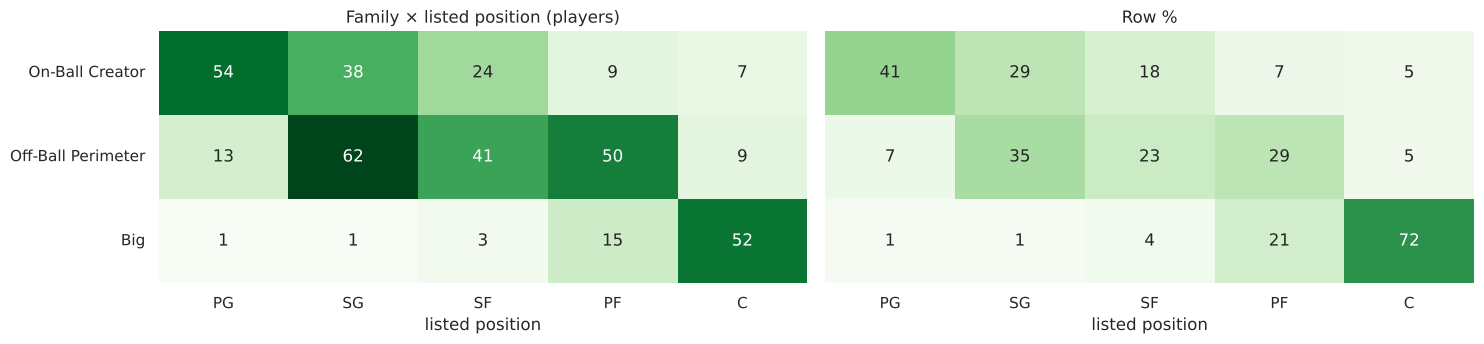

centres in the Big family: 52 of 68 (76%)
Big family that is listed C: 72%
PG in On-Ball Creator family: 79% | SG: 38% | SF: 35%


In [7]:
fam_ct = pd.crosstab(arch['family'], arch['pos']).loc[FAM_ORDER, POS_ORDER]
fam_row = fam_ct.div(fam_ct.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
sns.heatmap(fam_ct, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax[0])
ax[0].set(title='Family × listed position (players)', xlabel='listed position', ylabel='')
sns.heatmap(fam_row, annot=True, fmt='.0f', cmap='Greens', cbar=False, vmin=0, vmax=100, ax=ax[1])
ax[1].set(title='Row %', xlabel='listed position', ylabel=''); ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

bigs = arch['pos'].isin(['PF', 'C'])
print(f"centres in the Big family: {fam_ct.loc['Big', 'C']} of {fam_ct['C'].sum()} "
      f"({fam_ct.loc['Big', 'C'] / fam_ct['C'].sum():.0%})")
print(f"Big family that is listed C: {fam_ct.loc['Big', 'C'] / fam_ct.loc['Big'].sum():.0%}")
print(f"PG in On-Ball Creator family: {fam_ct.loc['On-Ball Creator', 'PG'] / fam_ct['PG'].sum():.0%} | "
      f"SG: {fam_ct.loc['On-Ball Creator', 'SG'] / fam_ct['SG'].sum():.0%} | "
      f"SF: {fam_ct.loc['On-Ball Creator', 'SF'] / fam_ct['SF'].sum():.0%}")

### Findings: Cross-tabulations
- **Only one archetype is essentially a position.** Rim-Running Big is 90% listed centres (28 of 31). Every other
  archetype has a purity of about 60% or less, and **Secondary Scoring Wing is the least pure (37%)**, drawing at
  least 15 players each from SF, SG and PF. Weighted by size, the average archetype is only about half made of its
  most common position.
- **Most archetypes span three or four positions.** Defensive Disruptor, Primary Creator, Spot-Up Floor Spacer and
  Stretch Forward each take at least three players from four different positions, and Secondary Scoring Wing from
  three.
- **Every position hides several jobs.** Counting archetypes that hold at least 10% of a position's players, PG
  splits into two, C into three, and SG, SF and PF into five each:
  - **C** splits into Rim-Running Big (41%), Hub Big (28%) and Stretch Forward (28%): three different jobs under one
    label.
  - **PG** is mostly Primary Creator (46%) or Shot-Making Guard (34%), but a sixth of point guards play off the ball
    (Spot-Up Floor Spacer or Defensive Disruptor).
  - **SG, SF and PF are the most mixed**: none of them sends more than about a third of its players to any single
    archetype.
- **Primary Creator is not a point-guard archetype**: 31 of its 61 players are listed PG, but the other 30 are listed
  SG, SF or PF.
- **Using the played position changes little.** The size-weighted purity is 50% either way; the main shifts are
  that Shot-Making Guards look more like point guards (purity 51% → 62%) and the most common position of Stretch
  Forwards becomes C instead of PF when actual minutes are used.
- **Families cut across positions too.** Big is 72% listed centres and holds 76% of all centres. On-Ball Creator
  holds 79% of point guards but draws from all five positions, and Off-Ball Perimeter holds the majority of SG, SF
  and PF players. Only the guard/centre ends of the position scale line up with a family.

---
## 4. What Do Archetypes Explain That Positions Don't?

**Goal.** For each of the 13 style features, compute **η² (eta-squared)**: the share of the feature's variance that is
explained by a grouping,

$$\eta^2 = \frac{\text{between-group sum of squares}}{\text{total sum of squares}} = 1 - \frac{\sum_i (x_i - \bar x_{g(i)})^2}{\sum_i (x_i - \bar x)^2}$$

η² is exactly the **R² of a linear regression of the feature on the group dummies**, so it reads like R²: 0 means
the groups have identical means, 1 means every player equals their group mean. It is computed in **real units** (raw
features) for the listed position, the played position, the 3 families and the 8 archetypes.

**Why it matters.** This is the key quantitative comparison of the project. ARI tells us that archetypes differ from
positions; η² tells us **which aspects of style** each system captures, feature by feature.

**What to look for.** Features where position does well (expected: size-related features such as rebounding, rim
share and blocks) and features where it does poorly (expected: on-ball creation such as usage). Do the archetypes do
better everywhere, or are there features where position wins?

In [8]:
def eta_sq(values, groups):
    v = pd.Series(np.asarray(values, dtype=float))
    g = pd.Series(np.asarray(groups))
    ok = v.notna() & g.notna()
    v, g = v[ok], g[ok]
    return 1 - ((v - v.groupby(g).transform('mean')) ** 2).sum() / ((v - v.mean()) ** 2).sum()

eta = pd.DataFrame({k: [eta_sq(raw[f], lab) for f in FEAT] for k, lab in LABELS.items()}, index=FEAT)
eta['archetypes − position'] = eta['8 archetypes'] - eta['listed position']
print('mean η² across the 13 features:')
print(eta.mean().round(3).to_string())
eta.sort_values('listed position', ascending=False).rename(index=SHOW).round(3)

mean η² across the 13 features:
listed position          0.274
played position          0.269
3 families               0.391
8 archetypes             0.543
archetypes − position    0.270


,listed position,played position,3 families,8 archetypes,archetypes − position
ORB%,0.546,0.537,0.607,0.704,0.159
DRB%,0.533,0.530,0.339,0.506,-0.027
BLK%,0.464,0.486,0.401,0.503,0.040
AST%,0.356,0.323,0.474,0.588,0.232
% 2s assisted,0.354,0.356,0.512,0.651,0.297
rim share,0.335,0.352,0.522,0.705,0.370
3PA rate,0.267,0.263,0.541,0.720,0.453
corner-3 rate,0.218,0.214,0.563,0.644,0.426
FT rate,0.152,0.148,0.263,0.439,0.286
TOV%,0.113,0.097,0.099,0.246,0.133


**Goal.** Visualise the comparison: one group of bars per feature, sorted by how well the listed position explains it.

**What to look for.** The gap between the grey bars (position) and the coloured bars (families, archetypes), and
whether it is largest for the creation and defence features.

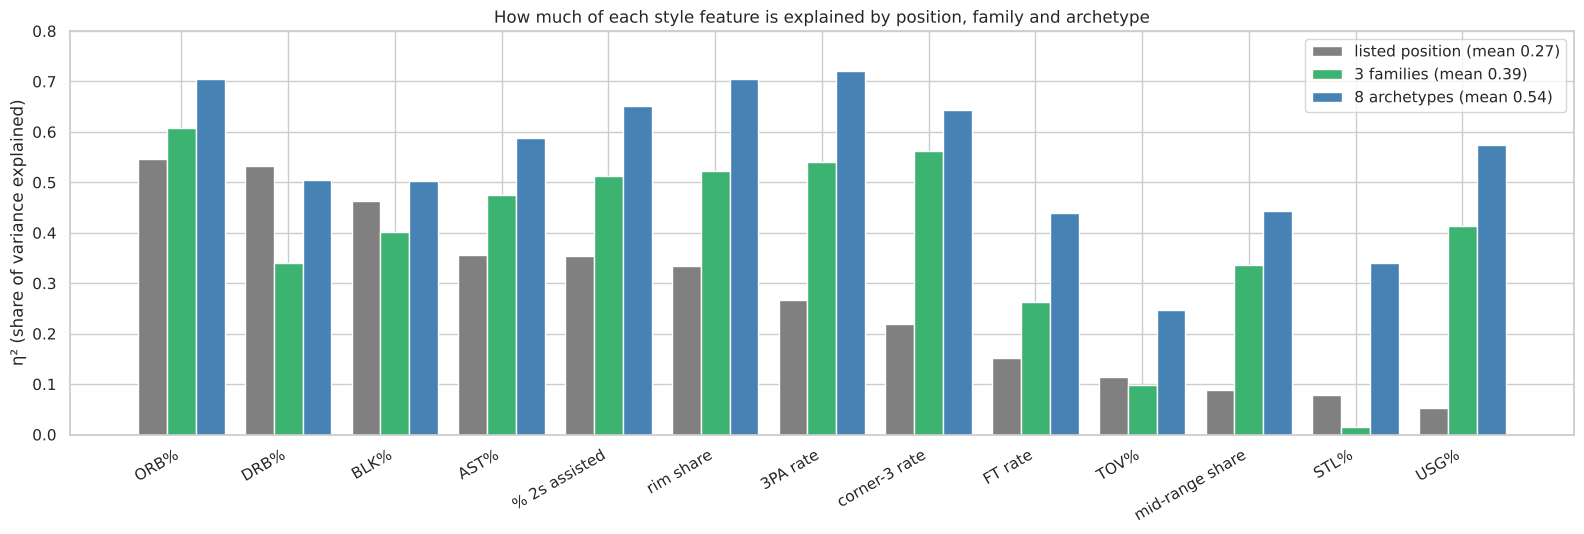

In [9]:
order = eta.sort_values('listed position', ascending=False).index
cols = {'listed position': 'grey', '3 families': 'mediumseagreen', '8 archetypes': 'steelblue'}
w = 0.27
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(16, 5.5))
for j, (k, c) in enumerate(cols.items()):
    ax.bar(x + (j - 1) * w, eta.loc[order, k], width=w, color=c, label=f'{k} (mean {eta[k].mean():.2f})')
ax.set_xticks(x); ax.set_xticklabels([SHOW[f] for f in order], rotation=30, ha='right')
ax.set(ylabel='η² (share of variance explained)', ylim=(0, 0.8),
       title='How much of each style feature is explained by position, family and archetype')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

**Goal.** Two fairness checks on the comparison.

1. **More groups always explain more.** Even random labels have η² > 0, and more random groups give a larger η². A
   permutation baseline (random labels with the same group sizes, 1,000 times) shows how much η² 5 or 8 groups earn
   by chance alone.
2. **Archetypes were built from these same 13 features**, so they are bound to explain them well. A fairer test uses
   **held-out descriptors of style that were never used for clustering**: average shot distance, dunk share, total
   rebound rate, scoring per 100 possessions, share of made threes assisted, fouls per 100, and the share of shots
   from 3–10 feet.

**What to look for.** Whether the chance level is small compared with the observed η², and whether archetypes still
beat positions on features they were not trained on.

In [10]:
rng = np.random.default_rng(SEED)
chance = {}
for k in ['listed position', '8 archetypes']:
    lab = LABELS[k].values
    chance[k] = np.mean([np.mean([eta_sq(raw[f], perm_lab) for f in FEAT])
                         for perm_lab in (rng.permutation(lab) for _ in range(N_PERM))])
print('mean η² expected by chance (shuffled labels, group sizes kept):',
      {k: round(v, 3) for k, v in chance.items()})
print('observed mean η²:', {k: round(eta[k].mean(), 3) for k in chance})

HELD_OUT = {'avg_dist_fga': 'average shot distance', 'percent_dunks_of_fga': 'dunks share of FGA',
            'trb_percent': 'total rebound %', 'pts_per_100_poss': 'points per 100 poss.',
            'percent_assisted_x3p_fg': '% of made 3s assisted', 'pf_per_100_poss': 'fouls per 100 poss.',
            'percent_fga_from_x3_10_range': 'share of FGA from 3–10 ft'}
held = pd.DataFrame({k: [eta_sq(full[c], lab) for c in HELD_OUT] for k, lab in LABELS.items()},
                    index=HELD_OUT.values())
held['archetypes − position'] = held['8 archetypes'] - held['listed position']
print('held-out features, missing values (players without a made 3 are skipped):',
      {v: int(full[c].isna().sum()) for c, v in HELD_OUT.items() if full[c].isna().any()})
print('mean η² on held-out features:', held.mean().round(3).to_dict())
held.round(3)

mean η² expected by chance (shuffled labels, group sizes kept): {'listed position': np.float64(0.011), '8 archetypes': np.float64(0.019)}
observed mean η²: {'listed position': np.float64(0.274), '8 archetypes': np.float64(0.543)}
held-out features, missing values (players without a made 3 are skipped): {'% of made 3s assisted': 16}
mean η² on held-out features: {'listed position': 0.281, 'played position': 0.278, '3 families': 0.401, '8 archetypes': 0.532, 'archetypes − position': 0.251}


,listed position,played position,3 families,8 archetypes,archetypes − position
average shot distance,0.332,0.338,0.550,0.731,0.399
dunks share of FGA,0.360,0.383,0.496,0.661,0.302
total rebound %,0.641,0.639,0.524,0.664,0.023
points per 100 poss.,0.021,0.010,0.288,0.450,0.429
% of made 3s assisted,0.326,0.299,0.498,0.582,0.256
fouls per 100 poss.,0.149,0.153,0.176,0.234,0.085
share of FGA from 3–10 ft,0.137,0.125,0.278,0.402,0.265


### Findings: Variance explained
- **Archetypes explain about twice as much style variance as positions.** Averaged over the 13 features, the listed
  position explains **η² ≈ 0.27**, the played position 0.27, the 3 families 0.39 and the 8 archetypes **0.54**.
- **Even 3 families beat 5 positions** on average (0.39 vs. 0.27), so the gain is not just a matter of having more
  groups. The chance level confirms this: shuffled labels give a mean η² of only about 0.01 (5 groups) and 0.02
  (8 groups).
- **Where position works:** the size features. Offensive and defensive rebounding (η² ≈ 0.55 and 0.53) and block rate
  (0.46) are the features position explains best.
- **Where position fails:** usage (η² ≈ 0.05), steal rate (0.08), mid-range share (0.09), turnover rate (0.11) and
  free-throw rate (0.15). Knowing a player's position tells you almost nothing about how much of the offense runs
  through them. Archetypes explain usage more than ten times better (0.57).
- **Position wins on one feature.** Defensive rebounding is explained slightly *better* by position (0.53) than by
  archetypes (0.51). Block rate is close as well (0.46 vs. 0.50). Height, which positions encode, drives these
  stats directly, and the archetypes split bigs by offensive role rather than by size.
- **The gain holds on held-out style descriptors** that played no part in clustering: archetypes explain average shot
  distance, dunk share and scoring rate much better than position (e.g. points per 100 possessions: η² ≈ 0.45 vs.
  0.02). Total rebound rate is again the exception, explained about equally well by both (≈ 0.66 vs. 0.64).
- **Conclusion:** the five positions are good at describing **size** and poor at describing **creation and
  disruption**, the same split that PCA found (position explains PC1 but hardly PC2–PC3).

---
## 5. Archetype Profiles in Real Units, and Value

**Goal.** Describe each archetype with the **median** of its style features in real units, and add efficiency and
impact statistics that were **never used for clustering**: true shooting % (TS%), Box Plus/Minus (BPM), win shares per
48 minutes (WS/48), value over replacement (VORP) and minutes played.

**Why it matters.** Archetype names are only useful if they correspond to recognisable basketball jobs. Adding value
stats tests a second claim: archetypes were built from *style* features only (shot diet, creation, rebounding,
defence), so they should describe **how** a player plays, not **how well**. If each archetype were a quality tier, the
"style" interpretation would be wrong.

**What to look for.** A distinct style fingerprint per archetype; and, for the value stats, whether the spread
*within* archetypes is much larger than the differences *between* them.

In [11]:
style_prof = raw[FEAT].groupby(arch['archetype']).median().loc[ORDER].rename(columns=SHOW)
style_prof.insert(0, 'players', arch['archetype'].value_counts().loc[ORDER])
for c in ['3PA rate', 'corner-3 rate', 'mid-range share', 'rim share', 'FT rate', '% 2s assisted']:
    style_prof[c] = (style_prof[c] * 100).round(0)        # shares shown as percentages
style_prof.round(1)

,players,3PA rate,corner-3 rate,mid-range share,rim share,FT rate,USG%,AST%,TOV%,% 2s assisted,ORB%,DRB%,BLK%,STL%
archetype,,,,,,,,,,,,,,
Primary Creator,61,34.0,5.0,20.0,20.0,29.0,25.9,25.9,13.5,34.0,2.7,13.2,1.1,1.9
Shot-Making Guard,45,51.0,8.0,19.0,12.0,18.0,21.1,20.7,13.1,39.0,2.1,10.2,0.7,1.5
Secondary Scoring Wing,57,42.0,11.0,14.0,21.0,26.0,20.4,12.7,10.9,58.0,3.6,12.7,1.1,1.5
Spot-Up Floor Spacer,48,70.0,20.0,8.0,12.0,13.0,15.2,9.6,9.2,71.0,2.8,10.3,1.0,1.3
Defensive Disruptor,50,50.0,18.0,6.0,24.0,20.0,15.3,12.6,13.0,56.0,4.8,12.6,1.5,2.4
Stretch Forward,56,45.0,16.0,4.0,32.0,23.0,16.6,8.4,11.0,70.0,6.6,17.7,2.6,1.5
Hub Big,31,19.0,3.0,15.0,33.0,36.0,23.4,17.7,13.5,58.0,8.3,23.4,3.0,1.6
Rim-Running Big,31,1.0,0.0,4.0,63.0,40.0,13.7,8.9,14.0,69.0,13.4,21.2,4.1,1.5


**How to read it.** Shot-diet columns are percentages of field-goal attempts (FT rate is free-throw attempts per 100
field-goal attempts; % 2s assisted is the share of made twos that were assisted). The other columns are the usual
Basketball-Reference rate stats (% of possessions or available rebounds, etc.).

**Goal.** Now the value side: median TS%, BPM, WS/48, VORP and minutes per archetype, and the η² of each value stat
for position vs. archetype.

**What to look for.** Whether the archetypes with the highest medians also contain many below-average players (wide
boxes), which would mean the archetype says little about quality on its own.

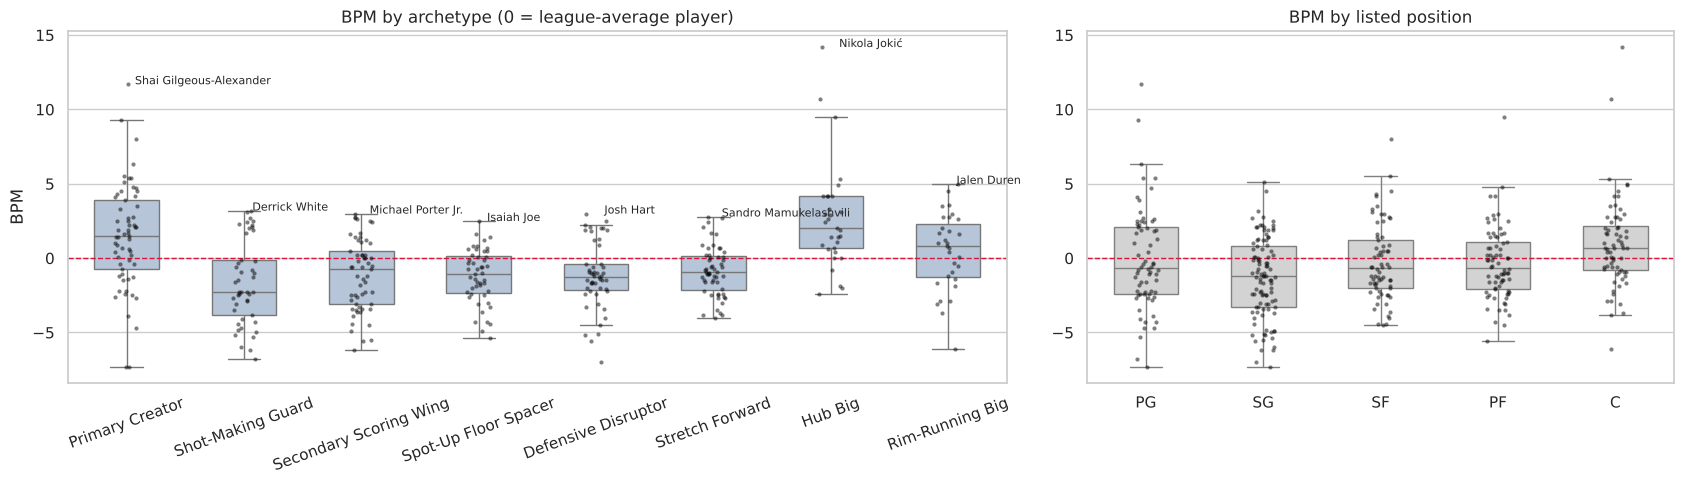

η² of value stats (share of variance explained):
         listed position  8 archetypes
TS%                0.167         0.289
BPM                0.065         0.215
WS/48              0.157         0.242
VORP               0.044         0.205
minutes            0.019         0.072


,TS%,BPM,WS/48,VORP,minutes,BPM range (min … max)
archetype,,,,,,
Primary Creator,0.573,1.5,0.112,1.3,1752.0,-7.3 … +11.7
Shot-Making Guard,0.556,-2.3,0.059,-0.1,1320.0,-6.8 … +3.2
Secondary Scoring Wing,0.581,-0.7,0.083,0.4,1689.0,-6.2 … +3.0
Spot-Up Floor Spacer,0.597,-1.0,0.086,0.3,1377.0,-5.4 … +2.5
Defensive Disruptor,0.540,-1.2,0.080,0.2,1354.0,-7.0 … +3.0
Stretch Forward,0.590,-1.0,0.102,0.4,1192.0,-4.0 … +2.8
Hub Big,0.592,2.0,0.144,1.6,1818.0,-2.4 … +14.2
Rim-Running Big,0.664,0.8,0.156,0.9,1234.0,-6.1 … +5.0


In [12]:
VALUE = {'ts_percent': 'TS%', 'bpm': 'BPM', 'ws_48': 'WS/48', 'vorp': 'VORP', 'mp': 'minutes'}
val = full[list(VALUE)].rename(columns=VALUE)
val_prof = val.groupby(arch['archetype']).median().loc[ORDER]
val_prof['BPM range (min … max)'] = [f"{val['BPM'][arch['archetype'] == a].min():+.1f} … "
                                      f"{val['BPM'][arch['archetype'] == a].max():+.1f}" for a in ORDER]
val_eta = pd.DataFrame({k: [eta_sq(val[c], LABELS[k]) for c in VALUE.values()]
                        for k in ['listed position', '8 archetypes']}, index=VALUE.values())

fig, ax = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={'width_ratios': [1.6, 1]})
sns.boxplot(x=arch['archetype'], y=val['BPM'], order=ORDER, color='lightsteelblue', fliersize=0, width=0.55, ax=ax[0])
sns.stripplot(x=arch['archetype'], y=val['BPM'], order=ORDER, color='black', size=3, alpha=0.5, ax=ax[0])
ax[0].axhline(0, color='crimson', lw=1, ls='--')
for a in ORDER:
    i = val['BPM'][arch['archetype'] == a].idxmax()
    ax[0].annotate(names[i], (ORDER.index(a), val['BPM'][i]), xytext=(6, 0), textcoords='offset points', fontsize=8)
ax[0].set(title='BPM by archetype (0 = league-average player)', xlabel='', ylabel='BPM')
ax[0].tick_params(axis='x', rotation=20)
sns.boxplot(x=arch['pos'], y=val['BPM'], order=POS_ORDER, color='lightgrey', fliersize=0, width=0.55, ax=ax[1])
sns.stripplot(x=arch['pos'], y=val['BPM'], order=POS_ORDER, color='black', size=3, alpha=0.5, ax=ax[1])
ax[1].axhline(0, color='crimson', lw=1, ls='--')
ax[1].set(title='BPM by listed position', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

print('η² of value stats (share of variance explained):')
print(val_eta.round(3).to_string())
val_prof.round({'TS%': 3, 'BPM': 1, 'WS/48': 3, 'VORP': 1, 'minutes': 0})

### Findings: Archetype profiles and value
Each archetype has a clear, recognisable style fingerprint (medians in the profile table):

| Archetype | Style in one line |
|---|---|
| **Primary Creator** | Highest usage and assist rate (both ≈ 26%); creates most of their own twos (only about a third assisted); the most mid-range of any group (≈ 20% of shots) |
| **Shot-Making Guard** | High usage (≈ 21%) with lead-guard passing (AST% ≈ 21) but a perimeter shot diet: half of shots are threes, only 12% at the rim, and the lowest rebound and block rates |
| **Secondary Scoring Wing** | Balanced, average-looking profile: usage ≈ 20%, 42% threes, 21% at the rim, no standout skill |
| **Spot-Up Floor Spacer** | 70% of shots are threes, the most corner threes (20% of all shots), low usage (≈ 15%); the highest share of twos assisted (71%) |
| **Defensive Disruptor** | Low usage (≈ 15%); the highest steal rate of any archetype (≈ 2.4%), a three-heavy diet, and more offensive rebounding than the other perimeter groups |
| **Stretch Forward** | Frontcourt rebounding and shot-blocking (BLK% ≈ 2.6) with ≈ 45% of shots from three: the floor-spacing big |
| **Hub Big** | Interior player who also runs the offense: usage ≈ 23%, AST% ≈ 18, the highest defensive rebound rate (≈ 23%) and the most free throws after rim-runners |
| **Rim-Running Big** | ≈ 63% of shots at the rim, almost no threes (1%), the highest offensive rebound (≈ 13%), block (≈ 4.1%) and free-throw rates, and the lowest usage (≈ 14%) |

- **Value differs by archetype, but far less than within it.** Archetype explains about 21% of the variance in BPM and
  24% in WS/48, so most of the quality variation is *within* archetypes. Every archetype contains players with a
  negative BPM, and the top BPM in Primary Creator (+11.7) and Hub Big (+14.2) belongs to the same archetypes that
  also hold players below −2.
- **The medians tell a coherent story.** Hub Bigs and Primary Creators have the highest median BPM (+2.0 and +1.5),
  partly because BPM rewards the box-score production these roles generate (usage, assists, rebounds). Rim-Running
  Bigs have the highest median TS% (≈ 0.66, from shots at the rim) and WS/48, yet a modest BPM. Shot-Making Guards
  have the lowest median BPM (−2.3) and WS/48 (0.059): high-usage perimeter scoring with few rim attempts, on the
  second-lowest TS% (0.556, above only the Defensive Disruptors).
- **Archetypes say more about value than positions do** (η² for BPM ≈ 0.21 vs. 0.07), because they capture role, and
  role drives box-score impact. But the main point stands: **archetypes describe style, not quality**. Knowing a
  player is a Primary Creator does not say whether they are Luka Dončić or a struggling backup.

---
## 6. Unicorns and Border Players vs. Positions

**Goal.** Cross-tabulate the anomaly categories from the previous notebook (statistical unicorn, unique hybrid, border
player, typical) against listed position and against archetype, and compare the **rate** of each category per
position.

**Why it matters.** If one position produced most of the league's unusual players, the five-position system would be
missing that position's variety in particular. Likewise, if border players concentrated in certain positions, those
positions would be the ones where the archetypes blur.

**What to look for.** Whether unicorns are spread evenly or concentrated, and whether border players come mainly from
the perimeter positions.

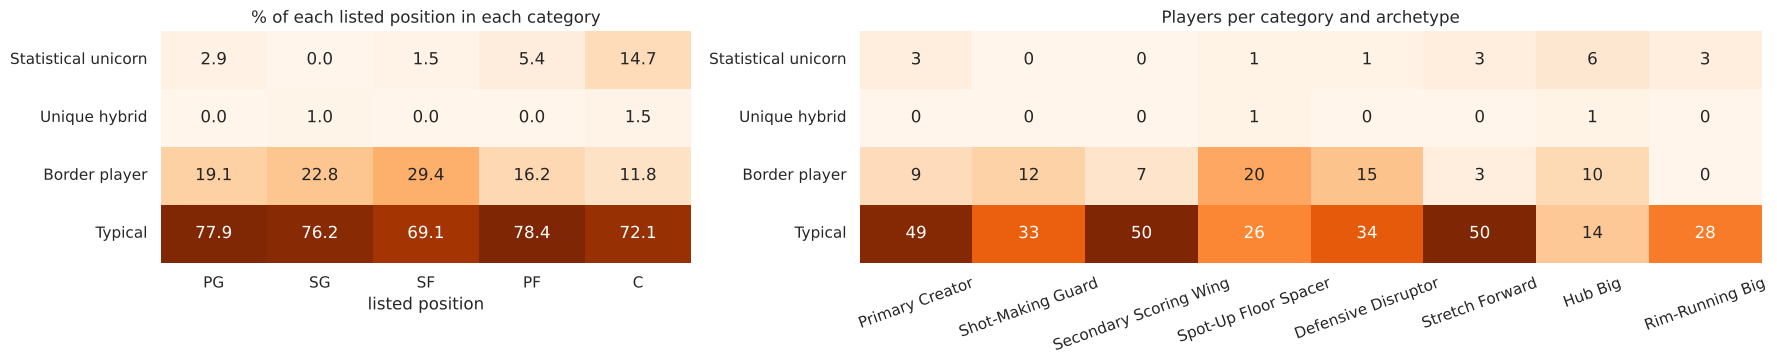

median anomaly score by listed position: {'PG': 0.52, 'SG': 0.42, 'SF': 0.42, 'PF': 0.48, 'C': 0.75}
median silhouette by listed position: {'PG': 0.122, 'SG': 0.115, 'SF': 0.084, 'PF': 0.134, 'C': 0.19}
unicorns + unique hybrids: 19, of which listed C: 11


pos,PG,SG,SF,PF,C
category,,,,,
Statistical unicorn,2,0,1,4,10
Unique hybrid,0,1,0,0,1
Border player,13,23,20,12,8
Typical,53,77,47,58,49


In [13]:
cat = anom['category']
CAT_ORDER = ['Statistical unicorn', 'Unique hybrid', 'Border player', 'Typical']
cat_pos = pd.crosstab(cat, arch['pos']).loc[CAT_ORDER, POS_ORDER]
cat_pos_rate = (pd.crosstab(cat, arch['pos'], normalize='columns').loc[CAT_ORDER, POS_ORDER] * 100).round(1)
cat_arch = pd.crosstab(cat, arch['archetype']).reindex(index=CAT_ORDER, columns=ORDER, fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(18, 3.8), gridspec_kw={'width_ratios': [1, 1.7]})
sns.heatmap(cat_pos_rate, annot=True, fmt='.1f', cmap='Oranges', cbar=False, ax=ax[0])
ax[0].set(title='% of each listed position in each category', xlabel='listed position', ylabel='')
sns.heatmap(cat_arch, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax[1])
ax[1].set(title='Players per category and archetype', xlabel='', ylabel='')
ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

print('median anomaly score by listed position:',
      anom['anomaly_score'].groupby(arch['pos']).median().loc[POS_ORDER].round(2).to_dict())
print('median silhouette by listed position:',
      arch['silhouette'].groupby(arch['pos']).median().loc[POS_ORDER].round(3).to_dict())
unicorns = anom.loc[cat.isin(['Statistical unicorn', 'Unique hybrid']), ['player', 'pos', 'archetype', 'category']]
print(f'unicorns + unique hybrids: {len(unicorns)}, of which listed C: {(unicorns["pos"] == "C").sum()}')
cat_pos

### Findings: Unicorns and border players
- **Statistical unicorns are concentrated among centres.** 10 of the 17 statistical unicorns (and 11 of the 19
  including unique hybrids) are listed C, about 15% of all centres, compared with 0–6% at the other positions. Centres
  also have by far the highest median anomaly score (0.75 vs. 0.42–0.52). The "centre" label covers the widest range
  of extreme profiles: rim-runners (Powell, Robinson, Sims), hubs (Jokić, Embiid, Wembanyama, Nurkić) and stretch bigs
  (Drummond, Huff, Stewart).
- **Border players are concentrated on the perimeter.** About 29% of small forwards and 23% of shooting guards are
  border players, against 12% of centres. The wings are where the archetypes blend into each other, consistent with
  SF having the lowest median silhouette (≈ 0.08) and C the highest (≈ 0.19).
- By archetype, border players gather in Spot-Up Floor Spacer (20), Defensive Disruptor (15) and Shot-Making Guard
  (12); Rim-Running Big has none. Statistical unicorns are most common among Hub Bigs (6 of 31).
- **The two kinds of misfit point in opposite directions.** Bigs are the most *distinct* players (unicorns, high
  silhouette); wings are the most *blended* (border players, low silhouette). Positions mislead in both cases: "C"
  lumps together very different extreme profiles, and "SF" / "SG" draw boundaries in the middle of a continuum.

---
## 7. Export

**Goal.** Save the validation results for reporting: the ARI table with permutation baselines, and the η² of every
style and held-out feature for each grouping.

| File | Contents |
|---|---|
| `validation_summary.csv` | One row per comparison: `section` (ARI / η² style feature / η² held-out / η² value), `item`, and one column per grouping (or the observed ARI, null mean, null max and z for the ARI rows) |

In [14]:
out = DATA / 'processed'
ari_rows = perm.assign(section='ARI', item=perm['grouping'] + ' vs. ' + perm['compared with'])
ari_rows = ari_rows[['section', 'item', 'observed ARI', 'null mean', 'null sd', 'null max', 'z vs. null']]
eta_rows = pd.concat([eta.drop(columns='archetypes − position').assign(section='eta2 style feature'),
                      held.drop(columns='archetypes − position').assign(section='eta2 held-out feature'),
                      val_eta.assign(section='eta2 value stat')]).rename_axis('item').reset_index()
summary = pd.concat([ari_rows, eta_rows], ignore_index=True)
summary.round(4).to_csv(out / 'validation_summary.csv', index=False)
print('saved', out / 'validation_summary.csv', summary.shape)
summary.groupby('section').size()

saved ../data/processed/validation_summary.csv (29, 11)


section
ARI                       4
eta2 held-out feature     7
eta2 style feature       13
eta2 value stat           5
dtype: int64

---
## 8. Conclusions

### What the five positions capture, and what they miss

| | Five positions | Data-driven archetypes |
|---|---|---|
| Agreement with each other | — | ARI ≈ 0.14–0.18: far above chance (z ≈ 41–52) but far from a relabelling (the two position labels agree at 0.54) |
| Size (rebounding, blocks, rim share; PCA axis 1) | **Captured well** (η² ≈ 0.46–0.55 for rebounding and blocks) | Captured equally well; position is slightly better on defensive rebounding |
| On-ball creation (usage, AST%; axis 2) | **Largely missed** (usage η² ≈ 0.05) | Captured (usage η² ≈ 0.57) |
| Disruption / shot diet (steals, mid-range, FT rate; axis 3) | **Missed** (η² ≤ 0.15) | Partly captured (η² ≈ 0.34–0.44) |
| Overall (mean η² across 13 features) | 0.27 | 0.54 (3 families: 0.39) |
| Quality (BPM) | η² ≈ 0.07 | η² ≈ 0.21: archetypes describe style, not quality |

### The project's main findings
1. **Positions are a one-dimensional description of a three-dimensional game.** PCA found three style axes (interior ↔
   perimeter, on-ball creator ↔ off-ball finisher, disruptor ↔ scorer). Position tracks the first, which is essentially
   size, and is nearly blind to the other two. This notebook confirms it feature by feature: positions explain
   rebounding and blocks, but almost nothing about usage, steals or the mid-range.
2. **Playing style is a continuum.** Silhouettes are low at every k, DBSCAN sees a single connected cloud, and about
   one player in five is a border player. Archetypes are useful *regions* of a continuous map, not separate species.
3. **A two-level taxonomy works.** The **3 families** (On-Ball Creator, Off-Ball Perimeter, Big) are the most robust
   structure in the data, and on their own already explain more style variance than five positions. The
   **8 archetypes** add useful detail. Their reliability varies: Rim-Running Big is sharply separated and stable;
   Secondary Scoring Wing is the unstable "no specialty" middle.
4. **Every position hides several jobs.** Centres split into rim-runners, hubs and stretch bigs; point guards into
   primary creators and shot-making guards (plus some off-ball players); SG, SF and PF each spread over five
   archetypes. Only the rim-running big corresponds to a single position.
5. **Unusual ≠ in-between.** Statistical unicorns are extreme versions of a role and are concentrated among centres;
   border players are ordinary profiles between two roles and are concentrated among wings.

### Limitations
- **Box-score data under-describes defence.** Only steals, blocks and rebounding enter the features; on-ball defence,
  switching and rim deterrence without a block are invisible, so defensive roles are the least reliable part of the
  taxonomy.
- **One season.** Roles change with team context, injuries and age; the archetypes describe 2025-26 only.
- **A 500-minute cut-off.** It stabilises rate stats but excludes low-minute and injured players, so archetypes for
  end-of-bench roles are under-represented.
- **k = 8 was chosen partly for interpretability.** The statistics support k = 3 most strongly; eight archetypes are a
  useful level of detail, not a uniquely correct number.
- **The η² comparison favours archetypes on the 13 clustering features** because k-means is built to separate them.
  The held-out features and the 3-family comparison reduce, but do not remove, this advantage.
- **Position labels are themselves noisy.** Two versions of position agree only at ARI ≈ 0.54, so a perfect match was
  never achievable.

**Bottom line.** The five positions are a good shorthand for *size*. Data-driven archetypes keep that information and
add the dimensions positions miss, above all **who creates the offense**. For describing how a modern NBA player
actually plays, a family + archetype label (with a fit score) is a more informative summary than a position.